# FilNet: solar filament segmentation with a network trained from nothing

Solar Filament Segmentation Challenge 2026 (IEEE BigData Cup, Kaggle). Team: J. Samadov, N. S. Dzhalilov, A. Habilov.

This notebook goes through the submitted pipeline and **builds the submitted file** from the fold models' saved probability maps:

1. **Data.** 707 GONG H$\alpha$ photographs (2048 × 2048), each outlined by one to three experts.
2. **Input.** A filament is darker than the quiet Sun around it, not dark in absolute terms. Each frame is turned, with fixed arithmetic, into seven channels: brightness; contrast against the quiet Sun at the same $\mu$ (limb darkening measured on the frame itself and divided out); darkness against the surroundings at two sizes (≈30 px and ≈130 px); heliographic latitude, longitude from the central meridian, and $\mu$.
3. **Model.** FilNet, a residual U-Net with six resolutions and 17.6 M weights, **trained from random initialisation** (no ImageNet, no other pre-training) on 512 px windows, half of them centred on a filament. One model per fold, trained on Kaggle T4 GPUs by the kernels `filament-filnet`, `filament-filnet-b`, `filament-filnet-c` (`kernels/aug_unet/filnet.py`).
4. **Inference.** Each fold model predicts the whole 2048 × 2048 frame, averaged over the 8 symmetries of the square (D4). The fold models' maps are averaged.
5. **Candidates.** Connected regions of the mean map above a threshold, nearby pieces joined, small ones dropped. Each candidate has 21 features: appearance, its place in a threshold/join grid, heliographic latitude and longitude, orientation.
6. **Selection rule.** Gradient-boosted trees predict each candidate's IoU with the experts from the 21 features. They are trained on the out-of-fold candidates (every photograph's candidates come from the fold model that never saw it), and candidates below a cut are discarded.

The technical report (`report/`) describes the method, the evaluation and what else we tried, including an ensemble of sixteen ImageNet-initialised models that scores the same on the public test set (`notebooks/pipeline.ipynb`).

**Running it.** Nothing here needs a GPU: the networks' probability maps were written by the training kernels.
- **On Kaggle:** attach the competition data and the outputs of the FilNet kernels listed below.
- **Locally:** put the competition data in `MAGFiLO_1.0_Kaggle_2026/` (`kaggle competitions download -c filament-segmentation-2026`, then unzip); the next cells download the kernels' outputs with the Kaggle CLI.

In [1]:
import hashlib, inspect, json, os, subprocess, sys, time
import multiprocessing as mp
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "kernels" / "aug_unet" / "filnet.py").exists())
CODE = REPO / "kernels" / "aug_unet"
sys.path.insert(0, str(CODE))

import run                   # data split, geometry, augmentation, PQ (imports torch before cv2)
import post_local as P       # reading the saved probability maps
import candidate_pool as C   # candidate filaments and their features
import kfold as K            # out-of-fold rows, the selection rule, the test CSV
import filnet as FN          # the network, its fixed input channels and its training loop
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn, torch

SETTING = (0.6, 3)        # (threshold, join radius in px) of the candidates
MIN_AREA = 100      # px
C.ONE_SETTING, C.POOL_MIN_AREA = SETTING, MIN_AREA
VIEW = "d4"
SUBMITTED_MD5 = ""   # set when re-running: the MD5 of the file this notebook wrote on Kaggle and we submitted
print(f"python {sys.version.split()[0]}, torch {torch.__version__}, numpy {np.__version__}, "
      f"opencv {cv2.__version__}, scikit-learn {sklearn.__version__}, on Kaggle: {ON_KAGGLE}")

python 3.13.18, torch 2.11.0+cpu, numpy 2.1.3, opencv 4.14.0, scikit-learn 1.6.1, on Kaggle: True


In [2]:
# the training kernels' outputs: each fold model's probability maps (validation and test, plain and D4)
KERNELS = ["filament-filnet", "filament-filnet-b", "filament-filnet-c"]
if ON_KAGGLE:
    SRC, D, OUT = Path("/kaggle/input"), Path("/tmp/fil_post"), Path("/kaggle/working")
else:
    SRC, D, OUT = REPO / "inputs", REPO / "inputs" / "work", REPO / "notebooks" / "out"
    for k in KERNELS:
        if not (SRC / k).exists():
            subprocess.run(["kaggle", "kernels", "output", f"jannatsamadov/{k}", "-p", str(SRC / k)], check=False)
OUT.mkdir(parents=True, exist_ok=True)
models = P.extract(SRC, D)
FIL = {0: "filnet_phys", 1: "filnet_phys_f1", 2: "filnet_phys_f2", 3: "filnet_phys_f3", 4: "filnet_phys_f4"}
FOLDS = [k for k in FIL if FIL[k] in models]
print("saved maps:", ", ".join(models))
print("FilNet fold models used:", [FIL[k] for k in FOLDS])

saved maps: filnet_phys, filnet_phys_f1, filnet_phys_f2, filnet_phys_f3, filnet_phys_f4, filnet_raw
FilNet fold models used: ['filnet_phys', 'filnet_phys_f1', 'filnet_phys_f2', 'filnet_phys_f3', 'filnet_phys_f4']


## 1. Data, and how much the experts disagree

Each training photograph was outlined by one to three experts. The scorer treats every expert's set as a separate ground truth and pools them. Two experts agree with each other at PQ 0.35 only, and they disagree mostly on **whether** a faint structure is a filament, not on where it lies.

707 training photographs, 8199 outlines; photographs by number of experts: {1: 411, 2: 145, 3: 151}


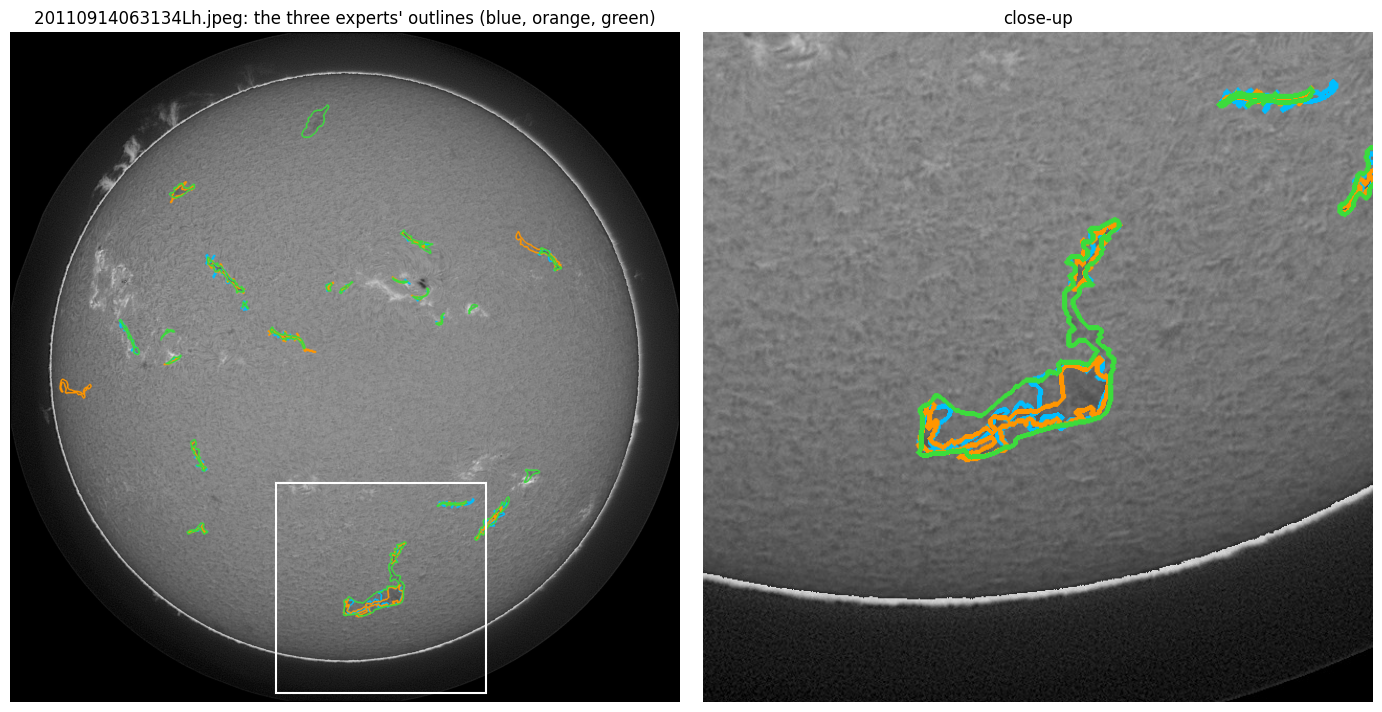

In [3]:
ann_path, tr_dir, te_dir = run.find_data()
coco = json.load(open(ann_path))
sets_of, by_set = {}, {}
for im in coco["images"]:                       # one entry per photograph and expert
    sets_of.setdefault(im["file_name"], []).append(im["id"])
for a in coco["annotations"]:
    by_set.setdefault(a["image_id"], []).append(a)
n_exp = np.bincount([len(v) for v in sets_of.values()])
print(f"{len(sets_of)} training photographs, {len(coco['annotations'])} outlines;",
      "photographs by number of experts:", {k: int(n) for k, n in enumerate(n_exp) if n})

three = sorted(f for f, s in sets_of.items() if len(s) == 3)
EXAMPLE = max(three, key=lambda f: sum(len(by_set.get(s, [])) for s in sets_of[f]))
img = cv2.imread(str(tr_dir / EXAMPLE), cv2.IMREAD_GRAYSCALE)
over = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
union = np.zeros(img.shape, np.uint8)
for col, sid in zip([(0, 190, 255), (255, 150, 0), (60, 220, 60)], sets_of[EXAMPLE]):
    for a in by_set.get(sid, []):
        m = run.ann_mask(a).astype(np.uint8)
        union |= m
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(over, cs, -1, col, 3)
n, lab, st, cen = cv2.connectedComponentsWithStats(cv2.dilate(union, np.ones((41, 41), np.uint8)))
cx, cy = cen[1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))].astype(int)
y0, x0 = int(np.clip(cy - 320, 0, 2048 - 640)), int(np.clip(cx - 320, 0, 2048 - 640))
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(over); ax[0].add_patch(plt.Rectangle((x0, y0), 640, 640, fill=False, ec="w", lw=1.5))
ax[0].set_title(f"{EXAMPLE}: the three experts' outlines (blue, orange, green)")
ax[1].imshow(over[y0:y0 + 640, x0:x0 + 640]); ax[1].set_title("close-up")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

## 2. The input: what a pixel is compared with

`filnet.front` turns a frame into the network's channels with fixed arithmetic (no weights):
- the **quiet-Sun profile** is the mean brightness in 48 rings of $\mu$, measured twice on the frame itself, the second time without the pixels that differ from the first profile by more than 12% (filaments, spots, plage);
- **contrast** = brightness / profile − 1, so a filament is about −0.2 anywhere on the disk;
- **local darkness** = contrast minus its mean over ≈30 px and over ≈130 px, means taken over disk pixels only;
- **position** = sin(latitude), longitude from the central meridian and $\mu$, from the disk geometry and the solar $B_0$ angle of the date.

@torch.no_grad()
def front(x, geo, arm):
    """x (B,1,H,W) in run.to_input units, geo (B,3,H,W) -> the network's input channels, whole frames."""
    if arm == "raw":
        return torch.cat([x, geo], 1)
    x, geo = x.float(), geo.float()
    v = x * 0.25 + 0.5                                   # brightness 0..1
    mu = geo[:, 2:3]
    on = (mu > 0.0).float()
    nb = 48
    idx = (mu.clamp(0.0, 0.9999) * nb).long().flatten(1)
    p1, _ = _ring_mean(v, on, idx, nb)                   # mean brightness in 48 rings of mu
    q1 = p1.gather(1, idx).view_as(v)
    quiet = on * ((v / q1.clamp(min=0.02) - 1.0).abs() < 0.12).float()   # again without filaments, spots, plage
    p2, n2 = _ring_mean(v, quiet, idx, nb)
    p2 = torch.where(n2 > 20, p2, p1)
    c = (v / p2.gather(1, idx).view_as(v).clamp(min=0.02) - 1.0).clamp(-1.0, 1.0) * on
    return torch.cat([x, 5.0 * c, 8.0 * _local(c, on, 4, 7), 6.0 * _local(c, on, 8, 15), geo], 1)



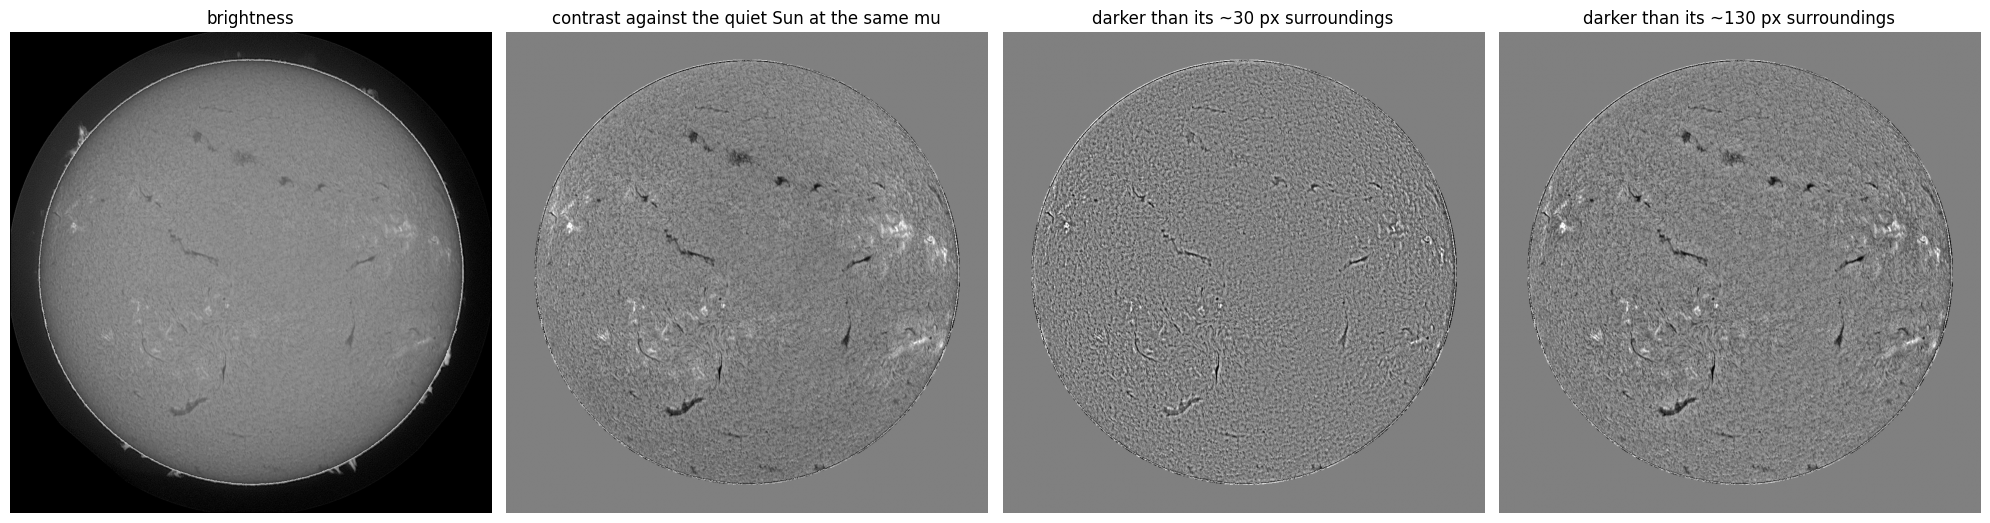

In [4]:
print(inspect.getsource(FN.front))
STEM = "20130530133654Bh"                         # the test photograph with the most filaments
img = cv2.imread(str(te_dir / f"{STEM}.jpeg"), cv2.IMREAD_GRAYSCALE)
geo = run.geo_channels(torch.tensor([[1.0, 0.0, 0.0, 1.0, run.b0_deg(STEM)]]), torch.device("cpu"))
ch = FN.front(run.to_input(img)[None, None], geo, "phys")[0].numpy()
names = ["brightness", "contrast against the quiet Sun at the same mu", "darker than its ~30 px surroundings",
         "darker than its ~130 px surroundings", "sin(latitude)", "longitude from the central meridian", "mu"]
fig, ax = plt.subplots(1, 4, figsize=(20, 5.3))
for a, k in zip(ax, range(4)):
    a.imshow(ch[k][::2, ::2], cmap="gray", vmin=-2, vmax=2); a.set_title(names[k]); a.axis("off")
plt.tight_layout(); plt.show()

## 3. The network and its training

- **Architecture:** a residual U-Net with six resolutions (1, 1/2, … 1/32) and widths 24, 48, 96, 192, 320, 384; full resolution is kept because a filament is about 8 px wide. No pre-trained weights and no attention.
- **Training windows:** 512 × 512 px cut from augmented full frames, every other one centred near a filament pixel, 12 per step.
- **Augmentation:** rotation by any angle about the disk centre, mirrors, contrast, gamma, brightness, blur or sharpening, noise and JPEG re-compression, within the ranges measured between GONG frames. The channels above are computed after the augmentation.
- **Target and loss:** the share of the photograph's experts who drew the pixel; BCE (positive weight 10) plus Tversky ($\alpha$ 0.6 on false positives, $\beta$ 0.4 on misses), at three resolutions (deep supervision).
- **Optimiser:** AdamW (lr $10^{-3}$, weight decay $10^{-2}$), two warm-up epochs then cosine decay; the model is the exponential moving average of the weights.
- **Cost:** one T4 GPU per fold, 3–4 hours (150 000–200 000 windows); 0.3 s per photograph for one pass.

In [5]:
net = FN.FilNet(FN.IN_CH["phys"])
print(f"FilNet: {sum(p.numel() for p in net.parameters()) / 1e6:.2f} M parameters, {FN.IN_CH['phys']} input channels, "
      f"widths {FN.WIDTHS}, blocks per size {FN.DEPTH}")
del net
print("\n" + inspect.getsource(FN.loss_one))
rows = []
for p in sorted(SRC.rglob("filnet_*.json")):
    r = json.load(open(p))
    rows.append({"model": p.stem, "epochs": r.get("epochs"), "windows seen": r.get("steps", 0) * r.get("batch", 0),
                 "PQ, one pass": round(r["plain"]["best"]["PQ"], 4), "PQ, D4": round(r["d4"]["best"]["PQ"], 4),
                 "s per photograph": r.get("sec_per_photo")})
print("Each fold model on its own validation photographs (fixed rules, best of a small grid), as its training kernel wrote it:")
pd.DataFrame(rows)

FilNet: 17.60 M parameters, 7 input channels, widths (24, 48, 96, 192, 320, 384), blocks per size (1, 2, 2, 2, 2, 2)

def loss_one(logit, y, w):
    """BCE + Tversky over the whole batch of windows (many hold no filament). Targets soft."""
    bce = F.binary_cross_entropy_with_logits(logit, y, pos_weight=torch.tensor(10.0, device=logit.device),
                                             reduction="none")
    bce = (bce * w).sum() / w.sum().clamp(min=1.0)
    p = torch.sigmoid(logit)
    tp, fp, fn = (p * y * w).sum(), (p * (1 - y) * w).sum(), ((1 - p) * y * w).sum()
    return bce + 1.0 - (tp + 1.0) / (tp + ALPHA * fp + BETA * fn + 1.0)

Each fold model on its own validation photographs (fixed rules, best of a small grid), as its training kernel wrote it:


,model,epochs,windows seen,"PQ, one pass","PQ, D4",s per photograph
0,filnet_phys_f3,66,111672,0.3900,0.3958,0.330
1,filnet_phys_f4,65,109980,0.3898,0.3973,0.307
2,filnet_phys,120,203040,0.4139,0.4176,0.316
3,filnet_raw,117,197964,0.4066,0.4079,0.288
4,filnet_phys_f1,88,148896,0.4170,0.4248,0.378
5,filnet_phys_f2,90,152280,0.4195,0.4197,0.308


`filnet_raw` is the control arm of fold 0: the same network and training with brightness and position only (4 channels), without the contrast and local-darkness channels.

## 4. Inference: the fold models' maps, averaged

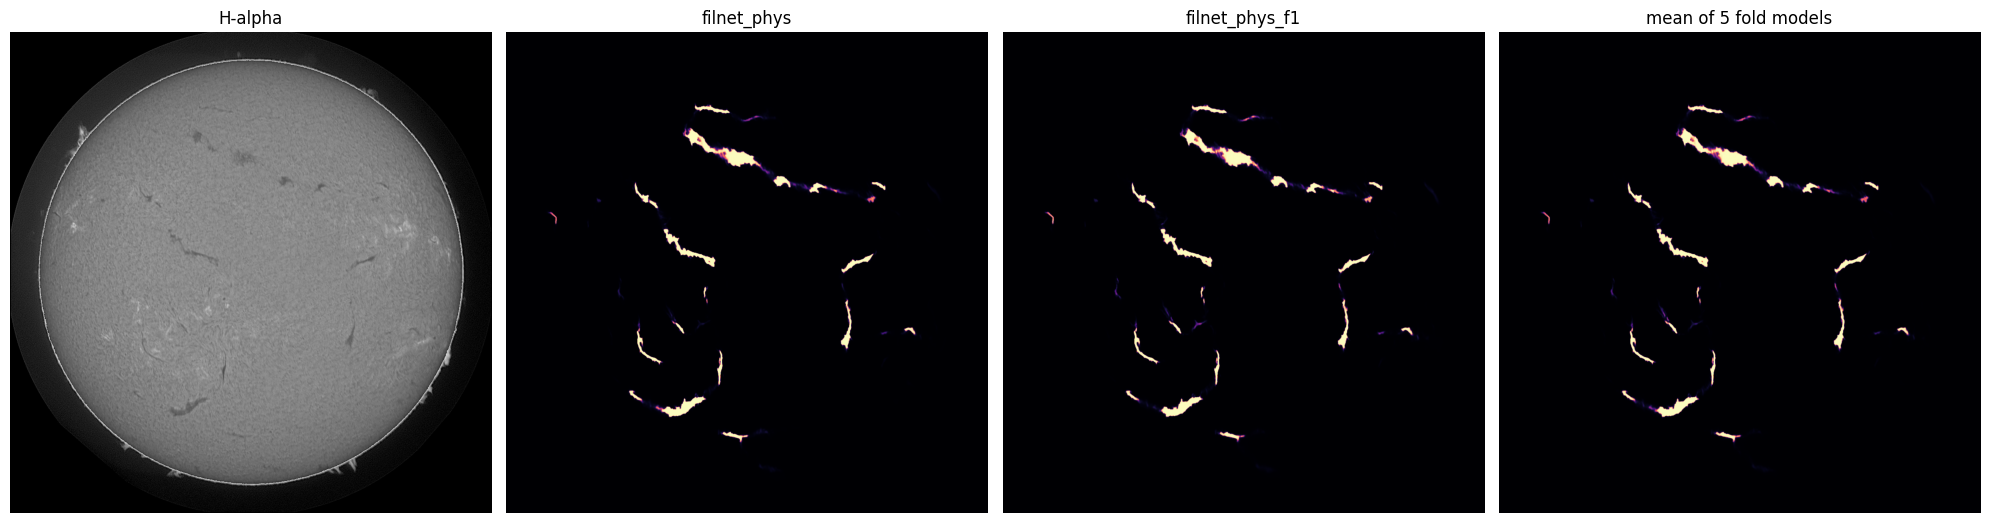

In [6]:
test_files = sorted(p.name for p in te_dir.glob("*.jpeg"))
test_stems = [Path(n).stem for n in test_files]
MEAN = "ens:" + "+".join(FIL[k] for k in FOLDS) + f"/{VIEW}"       # post_local.load_map averages the listed models
panels = [("H-alpha", img)] + [(FIL[k], P.load_map(D, f"{FIL[k]}/{VIEW}", "test", STEM)) for k in FOLDS[:2]] \
    + [(f"mean of {len(FOLDS)} fold models", P.load_map(D, MEAN, "test", STEM))]
fig, ax = plt.subplots(1, len(panels), figsize=(5 * len(panels), 5.3))
for a, (title, im) in zip(ax, panels):
    a.imshow(im[::2, ::2], cmap="gray" if title == "H-alpha" else "magma", vmin=0, vmax=255)
    a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Candidates and the selection rule, out of fold

For every training photograph the candidates come from the map of the fold model that never saw it. A candidate adds ½ to the denominator of PQ and its IoU to the numerator only if it is matched, so keeping it pays only if its probability of a match times its expected IoU exceeds PQ/2: the rule predicts that product (the candidate's mean matched IoU over the photograph's experts).

In [7]:
t0 = time.time()
truth = K.fold_truth(False)                     # every fold's validation photographs and expert sets
pool = mp.Pool(os.cpu_count() or 4)
cache = D / f"filnet_rows_{VIEW}"
cache.mkdir(parents=True, exist_ok=True)
jobs = [(str(D), f"{FIL[n]}/{VIEW}", stem, truth[n]["cache"], f, sets, str(cache), True)
        for n in FOLDS for f, stem, sets in truth[n]["frames"]]
frames = K.one_setting(list(pool.imap(K.pool_job, jobs)))
folds = np.concatenate([[n] * len(truth[n]["frames"]) for n in FOLDS])
COLS = K.GEO_COLS                               # the 21 features
print(f"{len(frames)} photographs out of fold, {sum(len(f['X']) for f in frames)} candidates at t {SETTING[0]}, "
      f"join {SETTING[1]} px, area >= {MIN_AREA} px; {time.time() - t0:.0f} s")

keep_all = K.counts_at_cuts(frames, [np.ones(len(f["X"])) for f in frames])[:, 0]
scores = [None] * len(frames)
for k in FOLDS:                                 # leave one fold out
    m = K.fit(frames, np.flatnonzero(folds != k), COLS, 0)
    for n in np.flatnonzero(folds == k):
        scores[n] = K.score(m, [frames[n]], COLS)[0]
counts = K.counts_at_cuts(frames, scores)
pq = K.pq_of(counts.sum(axis=0))
CUT = float(C.POOL_CUTS[int(np.argmax(pq))])
nested = K.rule_oof(frames, folds, COLS)        # each fold scored with the cut chosen on the other folds
table = [{"": "every candidate kept", **K.summary(keep_all.sum(axis=0))},
         {"": f"selection rule, cut {CUT} (chosen on these photographs)", **K.summary(counts[:, int(np.argmax(pq))].sum(axis=0))},
         {"": "selection rule, nested cut", **K.summary(nested.sum(axis=0))}]
for k in FOLDS:
    table.append({"": f"  fold {k}, nested cut", **K.summary(nested[folds == k].sum(axis=0))})
pd.DataFrame(table)

prepared 566 train / 141 val photographs (236 val annotation sets), 180 test, in 119s
prepared 566 train / 141 val photographs (228 val annotation sets), 180 test, in 104s
prepared 566 train / 141 val photographs (218 val annotation sets), 180 test, in 106s
prepared 566 train / 141 val photographs (242 val annotation sets), 180 test, in 108s
prepared 564 train / 143 val photographs (230 val annotation sets), 180 test, in 101s
707 photographs out of fold, 7748 candidates at t 0.6, join 3 px, area >= 100 px; 1312 s


,,PQ,SQ,RQ,TP,FP,FN
0,every candidate kept,0.3717,0.6709,0.5540,5761.0,6838.0,2438.0
1,"selection rule, cut 0.23 (chosen on these phot...",0.4438,0.6763,0.6562,5134.0,2314.0,3065.0
2,"selection rule, nested cut",0.4391,0.6788,0.6469,4777.0,1794.0,3422.0
3,"fold 0, nested cut",0.4456,0.6771,0.6581,1126.0,447.0,723.0
4,"fold 1, nested cut",0.4508,0.6795,0.6634,958.0,346.0,626.0
5,"fold 2, nested cut",0.4531,0.6818,0.6645,918.0,300.0,627.0
6,"fold 3, nested cut",0.4333,0.6769,0.6401,981.0,404.0,699.0
7,"fold 4, nested cut",0.4099,0.6793,0.6033,794.0,297.0,747.0


## 6. The submitted file

The rule is fitted on every out-of-fold candidate and applied to the candidates of the mean test map.

In [8]:
final = K.fit(frames, np.arange(len(frames)), COLS, 0)
name = f"submission_filnet{len(FOLDS)}_rule21.csv"
info = K.write_csv(D, MEAN, test_files, OUT / name, final, CUT, COLS)
ver = K.verify(OUT / name)
md5 = hashlib.md5((OUT / name).read_bytes()).hexdigest()
print(info, "\nMD5", md5)
if SUBMITTED_MD5:
    print("same as the submitted file:", md5 == SUBMITTED_MD5)

wrote submission_filnet5_rule21.csv: 1100 rows, 6.11 per image, 4 empty
verify submission_filnet5_rule21.csv: exit 0
rows: 1100
test images on disk: 180
decoded masks: 1100
mask area px: min 205 median 1408 max 21402   (train ground truth: median 1228)
filaments per image: mean 6.25 median 6 max 16   (train: mean 7.1, median 7)

WARN  4 test images have no prediction at all, e.g. ['20151204133714Th', '20170708164010Mh', '20200310113230Ch']

OK to submit (1 warning(s))

{'file': 'submission_filnet5_rule21.csv', 'rows': 1100, 'per_image': 6.111, 'empty': 4} 
MD5 f6e98d5ca4376d94364d5ea64ef96162


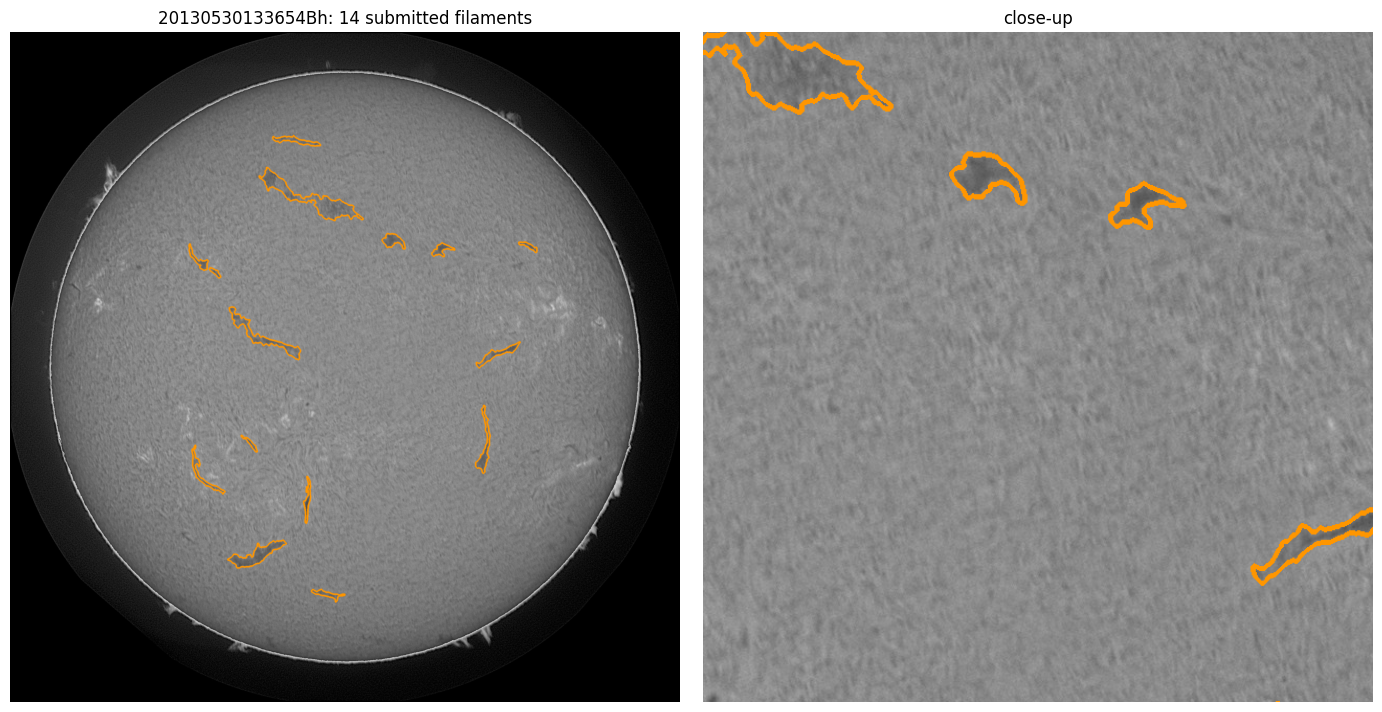

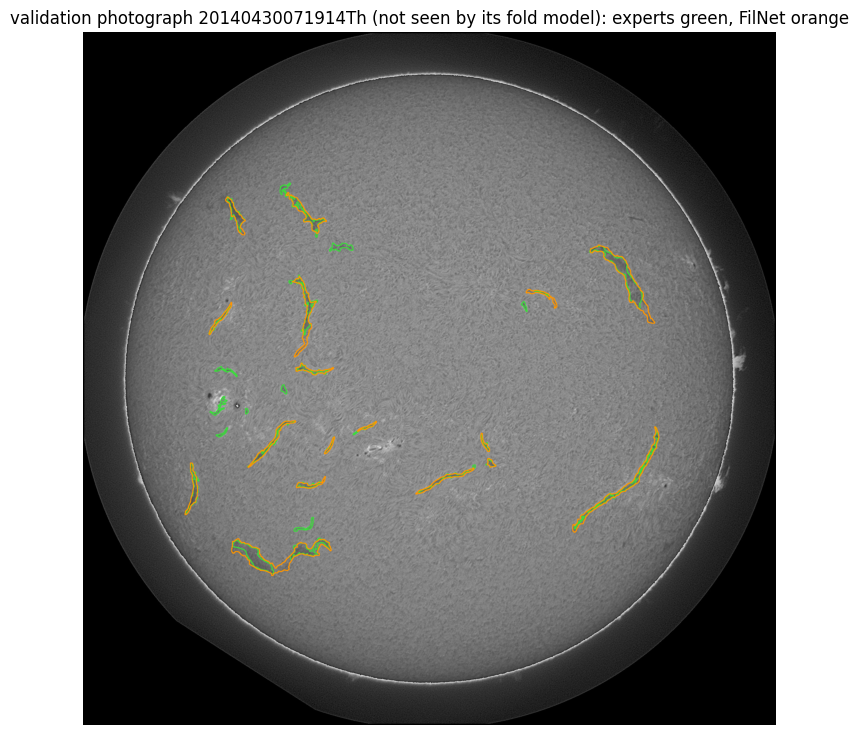

In [9]:
from pycocotools import mask as mu
sub = pd.read_csv(OUT / name)
rows_ = sub[sub.filament_id.str.startswith(STEM + "_")]
over = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
for rle in rows_.segmentation_rle:
    m = mu.decode({"size": [2048, 2048], "counts": rle.encode()})
    cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(over, cs, -1, (255, 150, 0), 3)
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(over); ax[0].set_title(f"{STEM}: {len(rows_)} submitted filaments")
ax[1].imshow(over[500:1140, 900:1540]); ax[1].set_title("close-up")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

# a validation photograph: the experts' outlines (green) and FilNet's kept candidates (orange)
n = int(np.flatnonzero(folds == FOLDS[0])[np.argmax([len(frames[i]["X"]) for i in np.flatnonzero(folds == FOLDS[0])])])
f = frames[n]
vimg = cv2.imread(str(tr_dir / f"{f['stem']}.jpeg"), cv2.IMREAD_GRAYSCALE)
over = cv2.cvtColor(vimg, cv2.COLOR_GRAY2RGB)
for sid in sets_of[f"{f['stem']}.jpeg"]:
    for a in by_set.get(sid, []):
        cs, _ = cv2.findContours(run.ann_mask(a).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(over, cs, -1, (60, 220, 60), 2)
for rle, s in zip(f["rle"], scores[n]):
    if s >= CUT:
        cs, _ = cv2.findContours(mu.decode(rle), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(over, cs, -1, (255, 150, 0), 2)
plt.figure(figsize=(9, 9)); plt.imshow(over); plt.axis("off")
plt.title(f"validation photograph {f['stem']} (not seen by its fold model): experts green, FilNet orange"); plt.show()

## 7. What the numbers mean

- **From nothing, FilNet equals an ImageNet-initialised U-Net twice its size.** With the same rule on the same photographs a ResNet-50 U-Net (32.5 M weights, ImageNet) reaches the same PQ within 0.001, and on the public test set FilNet scores 0.39, the same as our ensemble of sixteen ImageNet-initialised models (`notebooks/pipeline.ipynb`).
- **The physical channels matter.** The control arm without the contrast and local-darkness channels (`filnet_raw`, table in section 3) is lower on the same photographs, with and without the rule.
- **The ceiling is the experts' disagreement.** One expert scored against another reaches PQ 0.35. If the rule is replaced by what the *other* experts of the same photograph actually did with each candidate, PQ does not rise (0.443–0.449 against 0.446 for the rule); only the scored expert's own choices raise it (0.55–0.61). What remains is therefore one annotator's personal choice, which no image-based model can read.

The report lists the approaches that did not reach the submission.